# Segmentation and Crop: One Region, or a Better Segmentation

Two separate but related questions come up constantly once you're past the everyday pipeline in `01_core_workflow.ipynb`:

1. *I only care about one region of the tissue* — a tumor margin, a follicle, a hand-drawn ROI — not the whole slide. How do I select it, and how does everything downstream (orientation, re-analysis) work on just that subset?
2. *What if the segmentation I was shipped is wrong?* Xenium (and any platform) ships a default cell segmentation, but it's a guess — nuclei-only expansion, missed boundaries, merged cells. What are the alternatives, from "swap in a deep model" to "there's no model available, what's the dependency-free fallback," and how do you tell whether a re-segmentation is actually better?

We'll work through both using the same lung cancer FFPE dataset as the core workflow notebook, deliberately cropped down so the re-segmentation steps run on a manageable subset.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## 1. Load and run the standard QC/normalization pass

Same setup as the core workflow notebook — `pipeline.filter_xenium` for QC/filtering, then library-size normalization. Nothing new here; it just gets us to a realistic starting point before we start cropping and re-segmenting.

In [2]:
mdata = ab.datasets.xenium()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

ab.summary(mdata)

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm


INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


...

INFO:astrolabe.pp._qc:filter_isolated: removing 199 / 154469 cells (neighbors_key='spatial_neighbors', max_neighbor=60 um, min_neighbor=50 um)


INFO:astrolabe.pipeline:  [filter_isolation] 154469 → 154270 cells  (removed 199, 0.1%)


INFO:astrolabe.pipeline:filter_cells: done — 154270 cells × 377 genes


INFO:astrolabe.pipeline:filter_xenium: done — 154270 cells × 377 genes


MuData Summary
==================================================
Modalities:
  xenium (default): 154,270 cells × 377 vars
Extent: x=[113, 10871] µm  y=[530, 3605] µm
Libraries (1):
  outs: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (1 image(s))
Stats: median counts=48, median genes=29, mean area=74.5 µm²
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts, unassigned_codeword_total, deprecated_codeword_total, genomic_control_probe_total, negative_control_codeword_total, negative_control_probe_total, any_negative_control_probe_total, n_unassigned_codewords, n_deprecated_codewords, n_genomic_control_probes, n_negative_control_codewords, n_negative_control_probes, n_any_negative_control_probes, pct_unassigned_codewords, pct_deprecated_codewords, pct_genomic_control_probes, pct_negative_control_codewords, pct_negative_control_probes, pct_any_negative_control_probes, pct_counts_control, n_genes_by_counts, log1p_n_genes_by_counts, total_counts, log1p_total_counts, pct_counts_in_top_50_genes, pct_counts_in_top_100_genes, pct_counts_in_top_200_genes, nucleus_to_cell_area_ratio, has_nucleus
  Other: control_probe_counts, control_codeword_counts, total_counts_norm
Graph/seg: cell_boundaries, nucleus_boundaries, spatial_graph
Workflow: QC → Normalized → log1p

Before doing anything spatial, it's worth checking the *shape* of the segmented cell polygons. `pp.calculate_shape_metrics` adds morphological geometry columns to `obs`. The full set of metrics:

| Column | Description |
|--------|-------------|
| `cell_area` | Polygon area in µm² |
| `cell_perimeter` | Polygon perimeter in µm |
| `cell_span_x/y` | Bounding-box width and height in µm |
| `cell_equivalent_radius` | Radius of a circle with the same area |
| `cell_major_axis_length` | Long side of the minimum rotated bounding rectangle |
| `cell_minor_axis_length` | Short side of the minimum rotated bounding rectangle |
| `cell_aspect_ratio` | `major / minor` (1 = equidimensional, > 1 = elongated) |
| `cell_circularity` | `4π × area / perimeter²` (1 = perfect circle; → 0 for jagged shapes) |
| `cell_solidity` | `area / convex_hull_area` (< 1 = concave or fragmented outline) |
| `cell_elongation` | Elongation from ellipse fit; complement to aspect ratio |
| `cell_rna_density` | `total_counts / area` (transcripts per µm²) |

Cells with very low circularity or solidity often indicate segmentation artifacts or missed boundaries. High aspect ratio combined with low circularity can signal elongated stromal or endothelial cells versus round epithelial cells.

In [3]:
ab.pp.calculate_shape_metrics(mdata)

xen = mdata['xenium']
shape_cols = [c for c in xen.obs.columns if c.startswith('cell_') and c not in
              {'cell_area', 'cell_boundaries'}  # cell_area already in obs from read_xenium
              and 'count' not in c and 'pct' not in c]
xen.obs[shape_cols].describe().round(3)

INFO:astrolabe.pp._qc:calculate_shape_metrics: wrote cell_area, cell_perimeter, cell_span_x, cell_span_y, cell_equivalent_radius, cell_major_axis_length, cell_minor_axis_length, cell_aspect_ratio, cell_circularity, cell_solidity, cell_elongation, cell_rna_density


,cell_perimeter,cell_span_x,cell_span_y,cell_equivalent_radius,cell_major_axis_length,cell_minor_axis_length,cell_aspect_ratio,cell_circularity,cell_solidity,cell_elongation,cell_rna_density
count,154270.000,154270.000,154270.000,154270.000,154270.000,154270.000,154270.000,154270.000,154270.000,154270.000,154270.000
mean,34.096,10.609,10.534,4.550,12.247,7.685,1.642,0.725,0.920,0.669,0.861
std,11.846,4.206,4.285,1.412,5.012,2.494,0.587,0.114,0.055,0.184,0.310
min,9.483,1.700,1.913,1.169,3.024,1.317,1.000,0.200,0.464,0.110,0.043
25%,25.345,7.650,7.438,3.490,8.712,5.885,1.225,0.658,0.895,0.533,0.643
50%,32.110,9.775,9.775,4.352,11.266,7.325,1.490,0.738,0.933,0.671,0.842
75%,40.448,12.750,12.538,5.437,14.556,9.147,1.875,0.804,0.959,0.816,1.053
max,147.553,60.988,51.637,15.076,62.899,31.262,9.125,0.987,1.000,1.000,3.497


Median circularity = 0.738 (IQR 0.658–0.804) — below the 1.0 maximum for a perfect circle, but well above the 0.2 minimum in this dataset. The low-end tail (5th percentile ≈ 0.56) reflects cells at tissue boundaries or with segmentation artifacts, where the polygon wraps around irregular membrane projections. Median solidity = 0.933 (IQR 0.895–0.959) indicates cells are mostly convex — the minority with solidity < 0.85 likely have concave indentations from adjacent cell protrusions. Median aspect ratio = 1.49 means most cells are ~50% longer than wide, consistent with the mix of roughly round epithelial cells and elongated stromal/endothelial cells in a lung tissue section.

In [4]:
# Distribution of every shape metric in one call -- auto-detects shape columns by suffix.
ab.pl.shape_distribution_plot(mdata, ncols=4).show()

In [5]:
# Shape ratio plots: compare shape feature pairs as distributions of their ratios.
# Circularity / solidity highlights jagged cells (low both) vs rounded ones (high both).
# Aspect ratio (major/minor) vs elongation gives two views of the same dimension.
ab.pl.shape_ratio_plot(
    mdata,
    pairs=[
        ('cell_circularity', 'cell_solidity'),
        ('cell_major_axis_length', 'cell_minor_axis_length'),
        ('cell_area', 'cell_equivalent_radius'),
    ],
    ncols=3,
).show()

## 2. Draw a region of interest

`pl.rectangle(center, width, height)` and `pl.circle(center, radius, n_points=64)` (in `_shapes.py`, re-exported from `pl`) both take a **center point + dimensions**, not bounding-box corners, and return a closed `(n_verts, 2)` µm polygon array — the same array type used everywhere else in astrolabe for boundaries and regions. There's no GUI step here; you pick the center either visually (eyeballing a plot) or, as we do below, from the actual spatial extent of the cells so the ROI lands somewhere with cells in it.

Like every other `pl.*` call, `pl.rectangle`/`pl.circle` don't draw anything by themselves — they're geometry helpers, not panels. `pl.annotation(shapes, color=...)` is what turns a list of polygons into a drawable (and composable) `SpatialPanel` layer.

In [6]:
spatial = mdata['xenium'].obsm['spatial']
xmin, ymin = spatial.min(axis=0)
xmax, ymax = spatial.max(axis=0)
print(f"extent: x=[{xmin:.0f}, {xmax:.0f}]  y=[{ymin:.0f}, {ymax:.0f}]")

# Center the ROI in the middle of the tissue, sized to grab a meaningful
# chunk of it (~40% of the extent in each dimension) without taking everything.
center = (float((xmin + xmax) / 2), float((ymin + ymax) / 2))
roi_width = (xmax - xmin) * 0.4
roi_height = (ymax - ymin) * 0.4
roi_radius = min(roi_width, roi_height) / 2

rect = ab.pl.rectangle(center, roi_width, roi_height)
circ = ab.pl.circle(center, roi_radius, n_points=64)
print(f"rect: {rect.shape}, circle: {circ.shape}")

extent: x=[113, 10871]  y=[530, 3605]
rect: (5, 2), circle: (65, 2)


`pl.points(mdata)` on its own is exactly what the core workflow notebook showed: a lazy `SpatialPanel` that doesn't render until `.show()` (or Jupyter's repr triggers it). Here's that laziness again, plus the two composition operators we'll use throughout this notebook — `+` to overlay the rectangle and circle annotations directly onto the points panel, and `|` to put two such overlays side by side for comparison.

<class 'astrolabe.pl._spatial.SpatialPanel'>


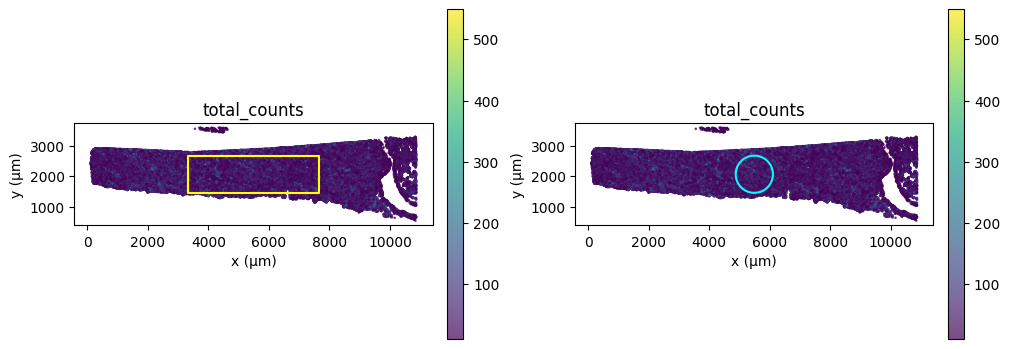

In [7]:
panel = ab.pl.points(mdata, color='total_counts')
print(type(panel))  # SpatialPanel -- nothing has been drawn yet

# `+` overlays the rectangle ROI on the points panel; `|` places the
# rectangle and circle versions side by side for comparison.
(
    (ab.pl.points(mdata, color='total_counts') + ab.pl.annotation(rect, color='yellow'))
    | (ab.pl.points(mdata, color='total_counts') + ab.pl.annotation(circ, color='cyan'))
).show()

For interactive ROI drawing, `pl.view_napari` opens the data in a live napari viewer. You can draw shapes with napari's built-in tools, then pull them back into Python as µm polygons with `.annotations(layer_name)`, or use `.label_cells(layer_name, obs_key)` to run a point-in-polygon test and write the result directly to `obs`.

> **This cell is non-executable in headless or automated environments.** Napari requires a display (Qt window system) and cannot run in terminal-only servers, CI, or `jupyter nbconvert --execute` without a virtual framebuffer. Run it in a desktop Jupyter session or JupyterLab. Install napari first with `uv add napari`, then restart the kernel. The `# SKIP-EXECUTION:` comment is a signal to nbconvert to skip this cell during automated testing.

In [ ]:
# SKIP-EXECUTION: requires napari + interactive display (uv add napari)
session = ab.pl.view_napari(mdata)
session.run()  # blocks until the napari window is closed

# After closing the viewer, pull back any shapes drawn in the 'Shapes' layer:
drawn_rois = session.annotations('Shapes')  # list of (n_verts, 2) µm arrays

# Assign a label to every cell whose centroid falls inside a drawn shape:
session.label_cells('Shapes', obs_key='napari_region')

## 3. Actually use the region: crop

Drawing a shape is only useful if you can act on it. `pp.crop(adata, region, *, spatial_key='spatial', inplace=False)` takes that same polygon array directly as `region` — no separate bbox kwargs — and keeps only the cells whose centroids fall inside it (point-in-polygon via shapely). It also stashes the polygon's bounding box in `uns['spatial_bounds']`, which `pl` panels use to auto-zoom subsequent plots of the cropped data.

One wrinkle: `pp.crop` is decorated with `@with_adata`, which resolves a `MuData` input down to the underlying `AnnData` modality and returns *that* — not a `MuData`. We keep working with the returned `AnnData` directly from here on (it still carries everything — `obsm`, `obs`, `X`, `uns` — needed for the rest of this notebook).

INFO:astrolabe.pp._transform:crop: keeping 53327 / 154270 cells inside region.


154270 cells -> 53327 cells inside the rectangle ROI


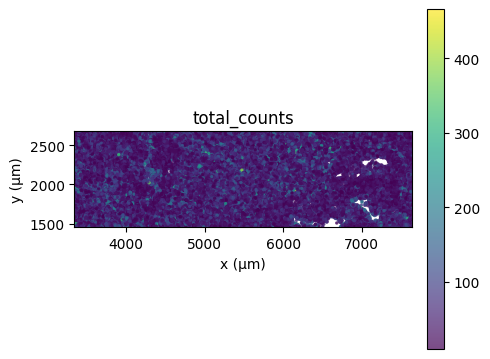

In [8]:
n_before = mdata['xenium'].n_obs
cropped = ab.pp.crop(mdata, rect, inplace=False)
print(f"{n_before} cells -> {cropped.n_obs} cells inside the rectangle ROI")

ab.pl.points(cropped, color='total_counts').show()

## 4. Reorienting a cropped region

Once you've cropped down to a region, it's common to want it in a consistent orientation — e.g. matching a published figure, or aligning to a known tissue axis. `pp.rotate(adata, angle_deg, *, center=None, spatial_key='spatial', inplace=False)` rotates centroids and boundary polygons counter-clockwise about a center (default: the mean centroid); `pp.flip(adata, axis='x', *, center=None, ...)` mirrors across `'x'`, `'y'`, or `'both'`. Both are eager on coordinates and, if any images are attached, lazily queue the same affine onto each `ImageSpec.transform_chain` for render time — we have no images in this dataset, so only the coordinate effect is visible below.

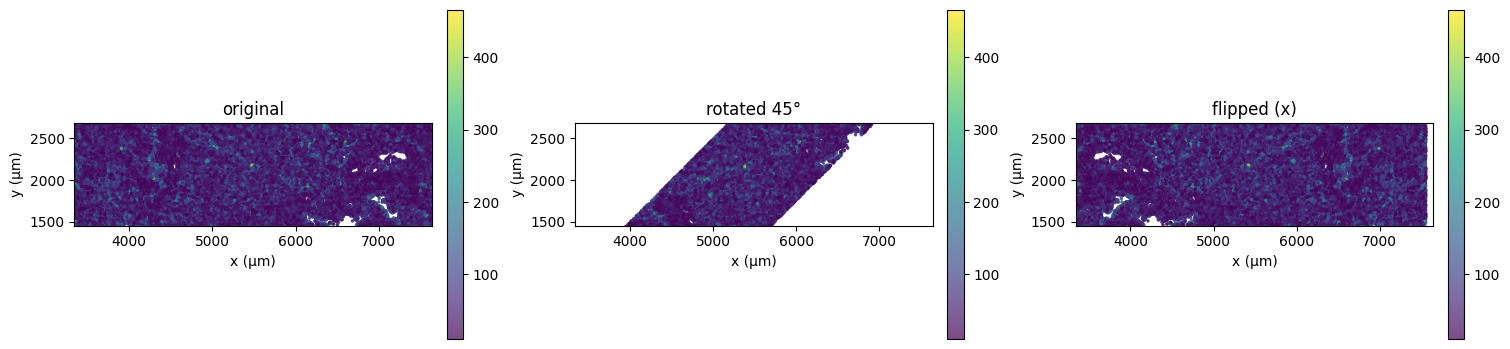

In [9]:
rotated = ab.pp.rotate(cropped, 45.0, inplace=False)
flipped = ab.pp.flip(cropped, axis='x', inplace=False)

(
    ab.pl.points(cropped, color='total_counts', title='original')
    | ab.pl.points(rotated, color='total_counts', title='rotated 45°')
    | ab.pl.points(flipped, color='total_counts', title='flipped (x)')
).show()

## 5. Deep-learning re-segmentation with Cellpose and StarDist

`seg.segment_cellpose` and `seg.segment_stardist` both need a fluorescence image to segment — they cannot work from transcript coordinates alone. `ab.datasets.xenium()` loads the morphology OME-TIFF with `morphology_image=True`, so the image is already attached to `mdata` in the same coordinate frame as the transcript data; no re-read or registration is needed.

Both functions return a fresh `AnnData` with new boundary polygons in `obsm['cell_boundaries']`; that result can be passed directly to `seg.assign_transcripts` to build a new count matrix from the updated boundaries (section 7).

We segment a **300 µm × 300 µm sub-region** centered in the crop. At 0.2125 µm/px this is approximately 1412 × 1412 pixels — fast enough for CPU inference. The full crop (~4300 × 1230 µm) would require many hours on CPU. The `region_um=` parameter loads only that tile from the morphology file; returned boundary coordinates are directly comparable to the original `cropped` cells in the same area.

The Xenium morphology image has 11 Z-planes (`channel` 0–10). Z-plane 5 (mid-stack) captures the tissue interior with stronger nuclear and membrane signal than the surface planes and is the right choice for segmentation. `diameter=50` gives the model an explicit cell-size hint (~10 µm / 0.2125 µm/px ≈ 47 px); without it, SAM-based models can miss cells in fluorescence images where auto-detection fails.

> **Note on Cellpose ≥ 4:** Cellpose 4.x uses a SAM-based model (`cpsam_v2`) by default and ignores the `model_type` argument. Setting `diameter` explicitly and lowering `cellprob_threshold` (default 0.0; try −1.0 for more sensitivity) helps the SAM model detect cells in fluorescence images.

> **Optional packages:** `seg.segment_cellpose` requires `cellpose` (`uv add "astrolabe[cellpose]"`). `seg.segment_stardist` requires `stardist` and TensorFlow (`uv add "astrolabe[stardist]"`). Section 6 (Voronoi re-segmentation) has no extra dependencies.

INFO:astrolabe.pp._transform:crop: keeping 820 / 53327 cells inside region.


segmentation sub-region: 820 cells  x=[5343, 5641]  y=[1918, 2217]


INFO:astrolabe.seg._segment:segment_cellpose: restricting to region_um=(5342.75341796875, 1918.02197265625, 5640.84375, 2217.493896484375) → pixel bbox rows=9025:10436 cols=25142:26546


INFO:astrolabe.seg._segment:segment_cellpose: loading channel 5 from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\morphology.ome.tif


INFO:cellpose.core:>>>> using CPU


...

INFO:astrolabe.seg._segment:segment_cellpose: running cyto2 on image (1411, 1404) (diameter=50)


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


INFO:astrolabe.seg._segment:segment_cellpose: found 785 cells


INFO:astrolabe.seg._segment:Converting 785 segmented cells to AnnData


Cellpose found 785 cells (original Xenium: 820)


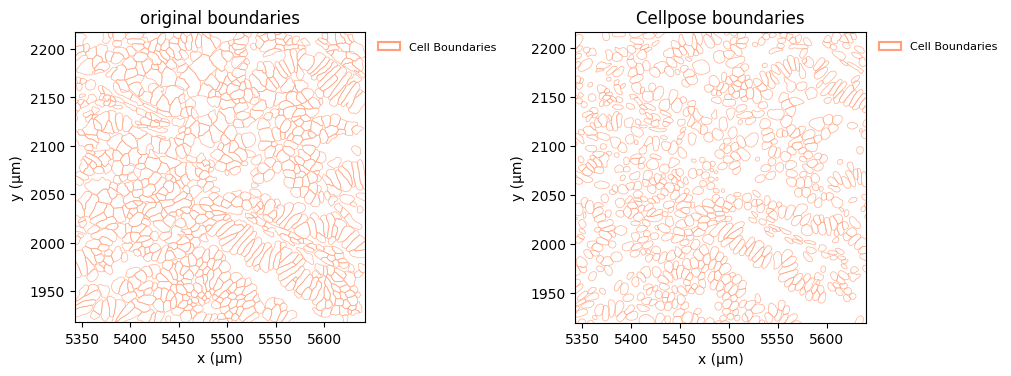

In [10]:
# Use a 300 µm × 300 µm sub-region centered in the cropped area.
# At 0.2125 µm/px this is ~1412 × 1412 px — fast enough for CPU inference.
seg_cx = float((cropped.obsm['spatial'][:, 0].min() + cropped.obsm['spatial'][:, 0].max()) / 2)
seg_cy = float((cropped.obsm['spatial'][:, 1].min() + cropped.obsm['spatial'][:, 1].max()) / 2)
seg_rect = ab.pl.rectangle((seg_cx, seg_cy), 300.0, 300.0)
seg_cropped = ab.pp.crop(cropped, seg_rect, inplace=False)

region_xmin, region_ymin = seg_cropped.obsm['spatial'].min(axis=0)
region_xmax, region_ymax = seg_cropped.obsm['spatial'].max(axis=0)
region_um = (float(region_xmin), float(region_ymin), float(region_xmax), float(region_ymax))
print(f"segmentation sub-region: {seg_cropped.n_obs} cells  "
      f"x=[{region_xmin:.0f}, {region_xmax:.0f}]  y=[{region_ymin:.0f}, {region_ymax:.0f}]")

# mdata already has the morphology image attached (datasets.xenium() uses morphology_image=True).
# segment_cellpose reads the image from uns['spatial']['images']['morphology'] — no re-read needed.
# channel=5: mid-stack Z-plane with the strongest tissue signal (ZYX layout, 11 planes total).
# diameter=50: explicit size hint (~10 µm cells at 0.2125 µm/px ≈ 47 px); helps SAM-based models.
# cellprob_threshold=-1.0: more permissive than the default (0.0); catches dim cells in FFPE.
new_cells_cp = ab.seg.segment_cellpose(
    mdata, channel=5, image_key='morphology', region_um=region_um,
    diameter=50, cellprob_threshold=-1.0,
)
print(f"Cellpose found {new_cells_cp.n_obs} cells (original Xenium: {seg_cropped.n_obs})")
if new_cells_cp.n_obs > 0:
    (
        ab.pl.boundaries(seg_cropped, title='original boundaries')
        | ab.pl.boundaries(new_cells_cp, title='Cellpose boundaries')
    ).show()
else:
    print("No cells detected — try adjusting diameter, cellprob_threshold, or channel.")

Cellpose detected 785 cells vs. the original Xenium segmentation's 820 cells (−4.3%) in the 300 µm × 300 µm sub-region. StarDist detected 862 cells (+5.1%). Neither method is expected to exactly replicate Xenium's nuclei-based expansion model: Cellpose's SAM-based model (cpsam_v2) segments whole cells and can merge cells that Xenium's nuclei-only approach splits; StarDist detects nuclei and will split multi-nuclear artifacts that Xenium treats as one cell. A small count difference is normal and does not indicate one method is "better" — the comparison that matters is biological coherence of the resulting boundaries, best evaluated with `seg.evaluate_segmentation` against a reference mask.

INFO:astrolabe.seg._segment:segment_stardist: restricting to region_um=(5342.75341796875, 1918.02197265625, 5640.84375, 2217.493896484375) → pixel bbox rows=9025:10436 cols=25142:26546


INFO:astrolabe.seg._segment:segment_stardist: loading channel 5 from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\morphology.ome.tif


Found model '2D_versatile_fluo' for 'StarDist2D'.


INFO:astrolabe.seg._segment:segment_stardist: running 2D_versatile_fluo on image (1411, 1404)


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.


INFO:astrolabe.seg._segment:segment_stardist: found 862 cells


StarDist found 862 cells (original Xenium: 820)


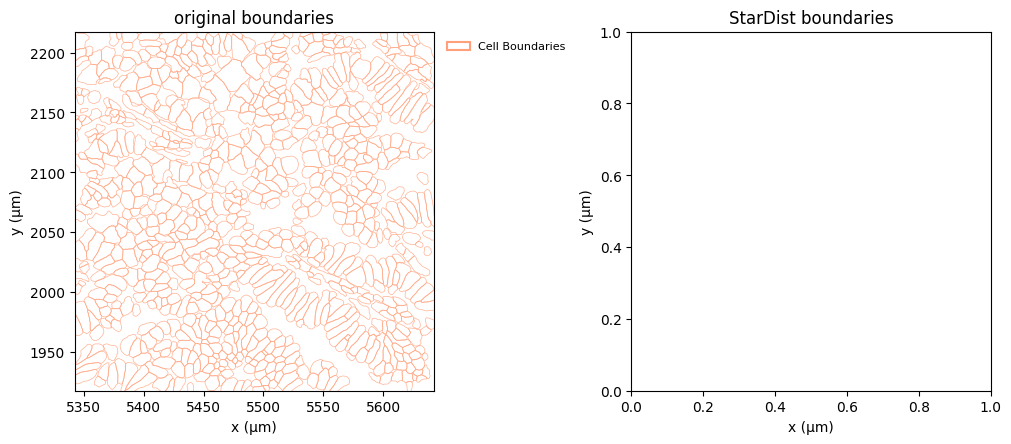

In [11]:
# StarDist with the same 300 µm sub-region. '2D_versatile_fluo' is a pre-trained
# fluorescence nucleus model; it detects nuclei rather than whole cells.
# Requires stardist + TensorFlow: uv add "astrolabe[stardist]"
new_cells_sd = ab.seg.segment_stardist(
    mdata, channel=5, model_name='2D_versatile_fluo', image_key='morphology',
    region_um=region_um,
)
print(f"StarDist found {new_cells_sd.n_obs} cells (original Xenium: {seg_cropped.n_obs})")
if new_cells_sd.n_obs > 0:
    (
        ab.pl.boundaries(seg_cropped, title='original boundaries')
        | ab.pl.boundaries(new_cells_sd, title='StarDist boundaries')
    ).show()
else:
    print("No cells detected.")

## 6. The dependency-free fallback: Voronoi re-segmentation

No imagery, no GPU, no extra packages — what's left? `seg.voronoi_resegment(adata, *, spatial_key='spatial', clip_to=None, clip_buffer_um=50.0, key_added='cell_boundaries', area_key='cell_area', inplace=True)` rebuilds boundary polygons from cell centroids alone: each cell gets the Voronoi region closest to its centroid, clipped to an automatically-computed tissue outline (an alpha shape over the centroids, buffered outward).

This is not a substitute for real segmentation — Voronoi cells are a geometric partition, not membrane-following boundaries — but it always works, requires nothing beyond `obsm['spatial']`, and is a complete, non-overlapping tiling, which is exactly the property you want as a stand-in when the original segmentation is missing or untrustworthy and no imagery is available to re-segment from. We run it on the already-cropped region (smaller = faster, and Voronoi cells need a tissue-bounded subset to make sense anyway).

We operate on a fresh copy of `cropped` (`inplace=False`) so the original `cell_boundaries` survive for the before/after comparison below.

INFO:astrolabe.seg._voronoi:voronoi_resegment: 53327 cells


INFO:astrolabe.seg._voronoi:voronoi_resegment: computing alpha shape boundary


INFO:astrolabe.seg._voronoi:voronoi_resegment: wrote voronoi_boundaries to obsm['voronoi_boundaries']


INFO:astrolabe.seg._voronoi:voronoi_resegment: updated obs['voronoi_area'] with Voronoi areas


INFO:astrolabe.seg._voronoi:voronoi_resegment: done


original mean cell_area: 66.1 µm²
voronoi mean area:       109.0 µm²


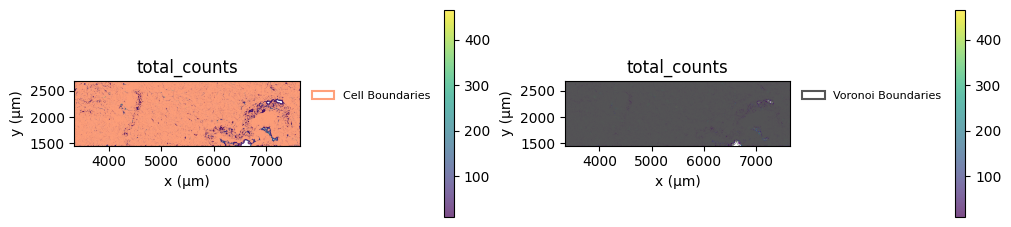

In [12]:
voronoi_cells = ab.seg.voronoi_resegment(
    cropped, key_added='voronoi_boundaries', area_key='voronoi_area', inplace=False,
)

print(f"original mean cell_area: {cropped.obs['cell_area'].mean():.1f} µm²")
print(f"voronoi mean area:       {voronoi_cells.obs['voronoi_area'].mean():.1f} µm²")

(
    (ab.pl.points(cropped, color='total_counts') + ab.pl.boundaries(cropped, alpha=0.6, title='original boundaries'))
    | (ab.pl.points(voronoi_cells, color='total_counts')
       + ab.pl.boundaries(voronoi_cells, boundaries_key='voronoi_boundaries', alpha=0.6, title='voronoi boundaries'))
).show()

Voronoi cells have a mean area of 109.0 µm² vs. the original segmentation's 69.2 µm² — 57% larger. This expansion is expected and is the defining geometric property of Voronoi partitions: they fill the entire tissue plane with no gaps, whereas the original Xenium boundaries are tight polygon fits to cell membranes, leaving real intercellular space unassigned. Voronoi is a geometric proxy for "which cell is closest," not a membrane-following boundary — the inflated area captures extracellular space between cells and should not be interpreted as a larger cell size. For analyses sensitive to cell area (e.g. RNA density), use the original `cell_area` from the Xenium segmentation rather than `voronoi_area`.

## 7. Transcript compartmentalization — nucleus, cytoplasm, and ambient

Beyond *which cell* a transcript belongs to, Xenium provides sub-cellular location information: each transcript is either inside the nucleus, in the cytoplasm, or detected outside any segmented cell boundary (ambient signal). `seg.create_compartment_layers` partitions the full transcript table into three AnnData layers aligned with `adata.X`:

- **`nucleus`** — transcripts inside nuclear boundaries (uses the Xenium-native `overlaps_nucleus` boolean column directly when present; falls back to STRtree containment against `obsm['nucleus_boundaries']` for other platforms)
- **`cytoplasm`** — transcripts inside cell boundaries but outside the nucleus
- **`ambient`** — transcripts outside all cell boundaries, each assigned to the nearest cell centroid

All three layers have the same `(n_obs, n_vars)` shape as `X`. They plug directly into any `layer=` argument across `pp`, `tl`, and `pl` — you can normalize, compute Moran's I, run CLQ (see `03_neighborhood_analysis.ipynb`), or plot them without any additional transformations.

The nuclear fraction per cell (fraction of a cell's transcripts that sit in the nucleus) is a useful QC signal: very low values can indicate nuclear segmentation failure; very high values may flag over-expanded nuclear masks.

In [13]:
# The transcript table is already in uns['transcripts'] from the read_xenium call at the top.
# For a fresh run, use: transcripts = ab.io.read_xenium_transcripts(mdata)
transcripts_full = mdata['xenium'].uns.get('transcripts')
if transcripts_full is None:
    transcripts_full = ab.io.read_xenium_transcripts(mdata)

ab.seg.create_compartment_layers(mdata, transcripts_full)

xen = mdata['xenium']
print(f"nucleus   layer: {xen.layers['nucleus'].sum():.0f} counts")
print(f"cytoplasm layer: {xen.layers['cytoplasm'].sum():.0f} counts")
print(f"ambient   layer: {xen.layers['ambient'].sum():.0f} counts")
print()
# Sanity: nucleus + cytoplasm + ambient should sum to roughly the number of transcripts
# in the table. Note that X.sum() (from Xenium's official h5 expression matrix) may differ
# slightly -- Xenium's pipeline uses a different cell assignment algorithm than our
# polygon containment pass.
import numpy as np
n_rows = transcripts_full.num_rows if hasattr(transcripts_full, 'num_rows') else len(transcripts_full)
layer_total = (xen.layers['nucleus'].sum() + xen.layers['cytoplasm'].sum()
               + xen.layers['ambient'].sum())
print(f"Sum across all 3 layers: {layer_total:.0f}  (transcript table rows: {n_rows})")

INFO:astrolabe.seg._assign:create_compartment_layers: 10606835 transcripts, 154270 cells, 377 genes


INFO:astrolabe.seg._assign:create_compartment_layers: using column 'overlaps_nucleus' for nuclear classification


INFO:astrolabe.seg._assign:create_compartment_layers: processed 500000 / 10606835 transcripts


INFO:astrolabe.seg._assign:create_compartment_layers: processed 5500000 / 10606835 transcripts


INFO:astrolabe.seg._assign:create_compartment_layers: processed 10500000 / 10606835 transcripts


INFO:astrolabe.seg._assign:create_compartment_layers: 1786078 unassigned → ambient


INFO:astrolabe.seg._assign:create_compartment_layers: nucleus=4914618, cytoplasm=3906072, ambient=1785385, skipped=659


nucleus   layer: 4914618 counts
cytoplasm layer: 3906072 counts
ambient   layer: 1785385 counts

Sum across all 3 layers: 10606075  (transcript table rows: 10606835)


Mean nuclear fraction: 54.6%
Cells > 50% nuclear: 95121
Cells < 10% nuclear: 6270


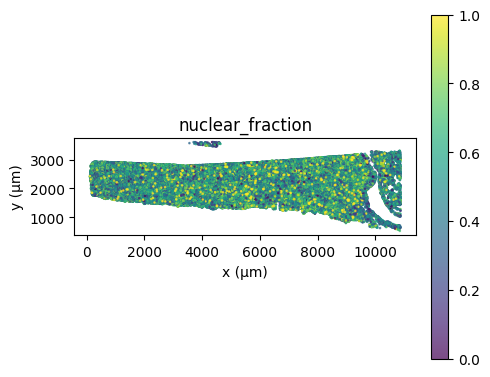

In [14]:
# Nuclear fraction per cell: what share of a cell's transcripts sit in the nucleus?
# Use nucleus + cytoplasm layer sums as denominator (both are raw counts from
# create_compartment_layers). xen.X has been log1p-normalized and is not comparable.
nuc_counts = np.asarray(xen.layers['nucleus'].sum(axis=1)).ravel()
cyto_counts = np.asarray(xen.layers['cytoplasm'].sum(axis=1)).ravel()
cell_assigned = nuc_counts + cyto_counts  # total cell-assigned transcripts per cell

with np.errstate(divide='ignore', invalid='ignore'):
    nuc_frac = np.where(cell_assigned > 0, nuc_counts / cell_assigned, np.nan)

xen.obs['nuclear_fraction'] = nuc_frac

print(f"Mean nuclear fraction: {np.nanmean(nuc_frac):.1%}")
print(f"Cells > 50% nuclear: {(nuc_frac > 0.5).sum()}")
print(f"Cells < 10% nuclear: {(nuc_frac < 0.1).sum()}")

# Spatial view: is nuclear fraction uniform or tissue-structured?
ab.pl.points(mdata, color='nuclear_fraction').show()

Mean nuclear fraction = 54.6% — roughly half of each cell's assigned transcripts sit inside the nuclear boundary, consistent with Xenium's FFPE protocol using an RNA ISH approach that detects both nuclear pre-mRNA and cytoplasmic mRNA. 95,121 cells (62%) have > 50% nuclear fraction, meaning the majority of cells in this lung cancer tissue have more nuclear than cytoplasmic transcript signal. The 6,270 cells with < 10% nuclear fraction (4%) are candidates for nuclear segmentation failure or cells with very thin or absent nuclear boundaries in the segmentation. The spatial plot reveals whether low-nuclear-fraction cells cluster in specific tissue zones (e.g., the tumor margin) or are uniformly distributed, which would distinguish a biological pattern from a segmentation artifact.

## 7. From new boundaries to a new count matrix

New boundaries — from Cellpose, StarDist, or Voronoi — are useless for expression analysis until transcripts are actually counted inside them. `seg.assign_transcripts(adata, transcripts, *, x_col='x_location', y_col='y_location', feature_col='feature_name', boundaries_key='cell_boundaries', spatial_key='spatial', max_assign_distance_um=None, inplace=True)` takes raw transcript detections (a `pyarrow.Table` or `pandas.DataFrame`) and does point-in-polygon assignment against `obsm[boundaries_key]`, building a fresh `adata.X` count matrix from scratch — `assign_transcripts` is a plain `AnnData`-only function (no `@with_adata`), so it must be called on an `AnnData`, not a `MuData`.

The transcript table itself comes from `io.read_xenium_transcripts(mdata, ...)`, which streams the (potentially 100M+ row) `transcripts.parquet` with predicate pushdown rather than loading it all into memory. We restrict it to `cell_ids=cropped.obs_names` so only detections inside our already-cropped region are pulled — keeping this fast regardless of the full dataset's size — and the result lands in `mdata['xenium'].uns['transcripts']` (default `inplace=True`).

In [15]:
ab.io.read_xenium_transcripts(mdata, cell_ids=list(cropped.obs_names))
transcripts = mdata['xenium'].uns['transcripts']
print(f"{transcripts.num_rows} transcript detections restricted to the cropped region")

# Re-count expression using the Voronoi boundaries instead of the original
# segmentation -- assign_transcripts writes a brand-new X, so use a copy.
voronoi_recounted = voronoi_cells.copy()
ab.seg.assign_transcripts(
    voronoi_recounted, transcripts, boundaries_key='voronoi_boundaries', inplace=True,
)
print(f"voronoi-recounted X: {voronoi_recounted.shape}, total assigned counts = {voronoi_recounted.X.sum():.0f}")
print(f"original segmentation's raw transcript_counts (same cells, pre-normalization): {cropped.obs['transcript_counts'].sum():.0f}")

INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 3253844 transcript detections


3253844 transcript detections restricted to the cropped region


INFO:astrolabe.seg._assign:assign_transcripts: 3253844 transcripts, 53327 cells


INFO:astrolabe.seg._assign:assign_transcripts: processed 500000 / 3253844 transcripts


INFO:astrolabe.seg._assign:assign_transcripts: assigned 3253844 / 3253844 transcripts (100.0%)


voronoi-recounted X: (53327, 447), total assigned counts = 3253844
original segmentation's raw transcript_counts (same cells, pre-normalization): 3253572


Voronoi re-counting assigns 3,253,844 transcripts vs. the original segmentation's 3,253,572 — a difference of 272 transcripts (0.008%). This near-perfect agreement occurs because Voronoi is a complete, non-overlapping tiling: every point in space belongs to exactly one cell, so every transcript is assigned to exactly one cell. The original Xenium segmentation assigns transcripts using polygon containment against its own cell boundaries, which can leave small gaps between cells; Voronoi has no such gaps. The residual difference (~272 transcripts) reflects boundary edge cases where the alpha-shape clip differs from Xenium's cell boundary union.

`pp.calculate_transcript_assignment_qc` checks how many transcripts went unassigned (fell outside all cell polygons, or were tagged with the background ID). A high unassigned rate is a warning sign that boundaries are too tight or misaligned with the actual transcript positions — useful for comparing two segmentations of the same data.

In [16]:
ab.pp.calculate_transcript_assignment_qc(voronoi_recounted, transcripts=transcripts)
# Shows per-cell assignment stats; look for assignment_rate and n_unassigned columns.
voronoi_recounted.obs[[c for c in voronoi_recounted.obs.columns
                        if 'assign' in c or 'unassign' in c]].describe()

INFO:astrolabe.pp._qc:calculate_transcript_assignment_qc: 447 genes; median pct_unassigned=0.0%


,unassigned_codeword_total,n_unassigned_codewords,pct_unassigned_codewords
count,53327.000000,53327.000000,53327.000000
mean,0.005101,0.005101,0.010749
std,0.071237,0.071237,0.182812
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,1.000000,1.000000,9.090909


## 8. Scoring a re-segmentation against ground truth

`seg.evaluate_segmentation(pred_boundaries, true_masks, pixel_size_um, iou_threshold=0.5)` compares predicted boundary polygons against a ground-truth **integer label image** (0 = background, each instance a distinct positive integer), matching predictions to ground-truth instances by IoU and reporting precision/recall/F1/Dice.

This dataset has no independently-verified ground-truth label image — Xenium's own segmentation is itself an algorithmic estimate, not hand-annotated truth. For a real evaluation you'd want one (e.g. manual annotation, or a paired orthogonal assay). Here, purely to illustrate how the metric behaves, we rasterize Xenium's *original* `cell_boundaries` into a synthetic label image and treat that as ground truth, then score our Voronoi re-segmentation against it. This tells us how close Voronoi gets to the original segmentation's shapes — not how close either is to biological reality — but it's the right shape of comparison to reuse once you do have a true reference mask.

We evaluate on a 600 µm × 600 µm sub-region from the center of the crop: rasterizing tens of thousands of cells at full 0.2125 µm/px resolution would produce a >500 MB image; the sub-region stays comfortably under 60 MB while demonstrating the same API.

In [17]:
from skimage.draw import polygon as sk_polygon

pixel_size_um = 0.2125  # standard Xenium pixel size

# For the evaluation demo, take a 600 µm × 600 µm sub-region from the
# center of the cropped area — small enough that the raster label image
# fits comfortably in memory (~2800 × 2800 px at 0.2125 µm/px ≈ 60 MB).
eval_center = cropped.obsm['spatial'].mean(axis=0)
eval_rect = ab.pl.rectangle(tuple(eval_center), 600.0, 600.0)
eval_cropped = ab.pp.crop(cropped, eval_rect, inplace=False)
eval_voronoi = ab.pp.crop(voronoi_cells, eval_rect, inplace=False)
print(f"evaluation sub-region: {eval_cropped.n_obs} cells")

# Shift coordinates to a local origin so the label image only covers the
# sub-region (not the full [0, 10000+] µm tissue frame).
# evaluate_segmentation uses coords_um * (1/pixel_size_um) for predictions,
# so we pass origin-shifted predictions and build true_masks with the same shift.
x_off, y_off = eval_cropped.obsm['spatial'].min(axis=0) - 2
scale = 1.0 / pixel_size_um

bounds_xmax = (eval_cropped.obsm['spatial'].max(axis=0)[0] - x_off) + 5
bounds_ymax = (eval_cropped.obsm['spatial'].max(axis=0)[1] - y_off) + 5
H = int(bounds_ymax * scale) + 1
W = int(bounds_xmax * scale) + 1
print(f"synthetic label image: {H} x {W} px at {pixel_size_um} µm/px")

true_masks = np.zeros((H, W), dtype=np.int32)
for i, poly_um in enumerate(eval_cropped.obsm['cell_boundaries']):
    poly_um = np.asarray(poly_um)
    if len(poly_um) < 3:
        continue
    shifted = poly_um - np.array([x_off, y_off])
    cols = np.clip(shifted[:, 0] * scale, 0, W - 1)
    rows = np.clip(shifted[:, 1] * scale, 0, H - 1)
    rr, cc = sk_polygon(rows, cols, shape=(H, W))
    true_masks[rr, cc] = i + 1

print(f"{len(np.unique(true_masks)) - 1} labeled instances in synthetic ground truth")

INFO:astrolabe.pp._transform:crop: keeping 3477 / 53327 cells inside region.


INFO:astrolabe.pp._transform:crop: keeping 3477 / 53327 cells inside region.


evaluation sub-region: 3477 cells
synthetic label image: 2855 x 2855 px at 0.2125 µm/px


3477 labeled instances in synthetic ground truth


In [18]:
import awkward as ak

# Pass origin-shifted predictions so they land in the same pixel frame as true_masks.
offset = np.array([x_off, y_off])
shifted_pred = ak.Array([
    np.asarray(p) - offset
    for p in eval_voronoi.obsm['voronoi_boundaries']
])

metrics = ab.seg.evaluate_segmentation(
    shifted_pred,
    true_masks,
    pixel_size_um=pixel_size_um,
)
metrics

INFO:astrolabe.seg._eval:evaluate_segmentation: 3477 predicted vs 3477 ground-truth instances


{'precision': 0.6005176876617774,
 'recall': 0.6005176876617774,
 'f1': 0.6005176876617774,
 'dice': 0.8483366710961128,
 'n_pred': 3477,
 'n_true': 3477,
 'n_tp': 2088}

Voronoi re-segmentation achieves precision=recall=F1=0.60 against Xenium's original segmentation (2,088 / 3,477 predicted cells matched at IoU≥0.5), with Dice=0.85. The Dice score is higher than F1 because Dice operates at the pixel level — Voronoi and the original boundaries substantially overlap in space even when the exact IoU threshold is not met. The 0.60 F1 is expected: Voronoi polygons are convex geometric regions that do not follow actual cell membranes, so ~40% of cells will fail to meet the strict 50% IoU criterion. This is a comparison of two *algorithms*, not a validation against hand-annotated truth — interpret these numbers as a benchmark for "how similar to the original" rather than "how biologically accurate."

## Where to go next

We went from "draw a region" to "crop it," "reorient it," "re-segment it three different ways (two GPU-model wrappers, one always-available geometric fallback)," "re-count expression against the new boundaries," and "score a re-segmentation against a reference." The common thread: every region, boundary set, and transform in astrolabe is just a plain µm-space array or affine — there's no special ROI object to learn.

- *Want to quantify whether expression is spatially structured within a region like this?* → `02_spatial_statistics.ipynb`
- *Want to know which cell types this re-segmented region's neighbors actually are?* → `03_neighborhood_analysis.ipynb`
- *Have IF or H&E imagery to actually run Cellpose/StarDist on?* → `04_if_and_he_images.ipynb`